# 00. Entendimiento y Preparación de los Datos
**Materia:** INF432 - Sistemas para el Soporte a la Toma de Decisiones  
**Proyecto:** Minería de datos para decisiones comerciales - RetailMarket Santa Cruz  
**Autor (Integrante 1):** Diogo Nicolas Rodríguez Gómez (Reg. 221045686)  

Este notebook realiza la carga inicial, auditoría de calidad, limpieza, ingeniería de variables derivadas, codificación, estandarización y división 70/30 sobre el conjunto de datos crudo para generar los datos procesados reproducibles.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Fijar semilla global obligatoria
SEMILLA = 1
np.random.seed(SEMILLA)

# Crear carpetas si no existen
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('reports/figures', exist_ok=True)

### 3.1 Carga del conjunto de datos crudo
Cargamos el archivo original desde la ruta relativa `data/raw/marketing_campaign.csv`. Este dataset utiliza tabulaciones (`\t`) como separador.

In [2]:
# Cargar datos crudos
df_raw = pd.read_csv('data/raw/marketing_campaign.csv', sep='\t')
print("Dimensiones originales (filas, columnas):", df_raw.shape)
df_raw.head()

Dimensiones originales (filas, columnas): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


### 3.2 Diagnóstico de Calidad de Datos
Auditamos valores faltantes, registros duplicados y tipos de datos por columna.

In [3]:
# Información general y tipos
df_raw.info()

# Revisar valores nulos
nulos = df_raw.isna().sum()
print("\n--- Valores faltantes por columna ---")
print(nulos[nulos > 0])

# Revisar duplicados exactos
duplicados = df_raw.duplicated().sum()
print(f"\nRegistros duplicados: {duplicados}")

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

### 4. Preparación de los Datos
1. **Faltantes en Income:** Se imputan con la mediana del ingreso según nivel educativo o se descartan (al ser solo 24 casos de 2.240, ~1%, la imputación por mediana preserva la muestra).
2. **Eliminación de columnas no informativas:** `ID` (identificador), `Z_CostContact` y `Z_Revenue` (constantes con varianza 0).
3. **Ingeniería de variables derivadas:**
   - `Age`: 2026 - `Year_Birth`.
   - `Total_Spent`: Suma de gastos en vinos, frutas, carnes, pescados, dulces y oro (`MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds`).
   - `Total_Purchases`: Suma de compras por web, catálogo y tienda física (`NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`).
   - `Children`: Suma de niños y adolescentes en casa (`Kidhome` + `Teenhome`).
   - `Family_Size`: Tamaño estimado del hogar según estado civil (`Marital_Status`) y cantidad de hijos.
   - `Customer_Days`: Días transcurridos como cliente desde `Dt_Customer`.
4. **Filtro de valores atípicos severos:** Clientes con `Age > 100` o ingresos anómalos extremos (`Income > 200000`).

In [4]:
df = df_raw.copy()

# 1. Tratar nulos en Income con la mediana
df['Income'] = df['Income'].fillna(df['Income'].median())

# 2. Filtrar atípicos lógicos
# Año actual de análisis: 2026
df['Age'] = 2026 - df['Year_Birth']
df = df[df['Age'] <= 100]
df = df[df['Income'] < 200000]

# 3. Variables derivadas
df['Total_Spent'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + 
                     df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

df['Total_Purchases'] = (df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases'])

df['Children'] = df['Kidhome'] + df['Teenhome']

# Simplificar estado civil
mapeo_marital = {
    'Married': 2, 'Together': 2, 
    'Single': 1, 'Divorced': 1, 'Widow': 1, 'Alone': 1, 'Absurd': 1, 'YOLO': 1
}
df['Family_Size'] = df['Marital_Status'].map(mapeo_marital) + df['Children']

# Antigüedad en días como cliente (asumiendo fecha de corte)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
fecha_referencia = df['Dt_Customer'].max()
df['Customer_Days'] = (fecha_referencia - df['Dt_Customer']).dt.days

# Simplificar Educación (Ordinal/Numérica)
# Basic: 0, 2n Cycle: 1, Graduation: 2, Master: 3, PhD: 4
mapeo_edu = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
df['Education_Level'] = df['Education'].map(mapeo_edu)

# 4. Eliminar columnas innecesarias o constantes
columnas_descartar = ['ID', 'Year_Birth', 'Dt_Customer', 'Education', 'Marital_Status', 'Z_CostContact', 'Z_Revenue']
df = df.drop(columns=columnas_descartar)

print("Dimensiones tras limpieza:", df.shape)

Dimensiones tras limpieza: (2236, 29)


### 3.3 Visualización y Distribución
Generamos el gráfico de barras de la variable objetivo supervisada (`Response`) y la matriz de correlación entre los gastos y la respuesta del cliente.

C:\Users\DELL\AppData\Local\Temp\ipykernel_4568\3192120199.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Response', data=df, ax=axes[0], palette=['#4A90E2', '#E94E77'])
C:\Users\DELL\AppData\Local\Temp\ipykernel_4568\3192120199.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Response', y='Total_Spent', data=df, ax=axes[1], palette=['#4A90E2', '#E94E77'])


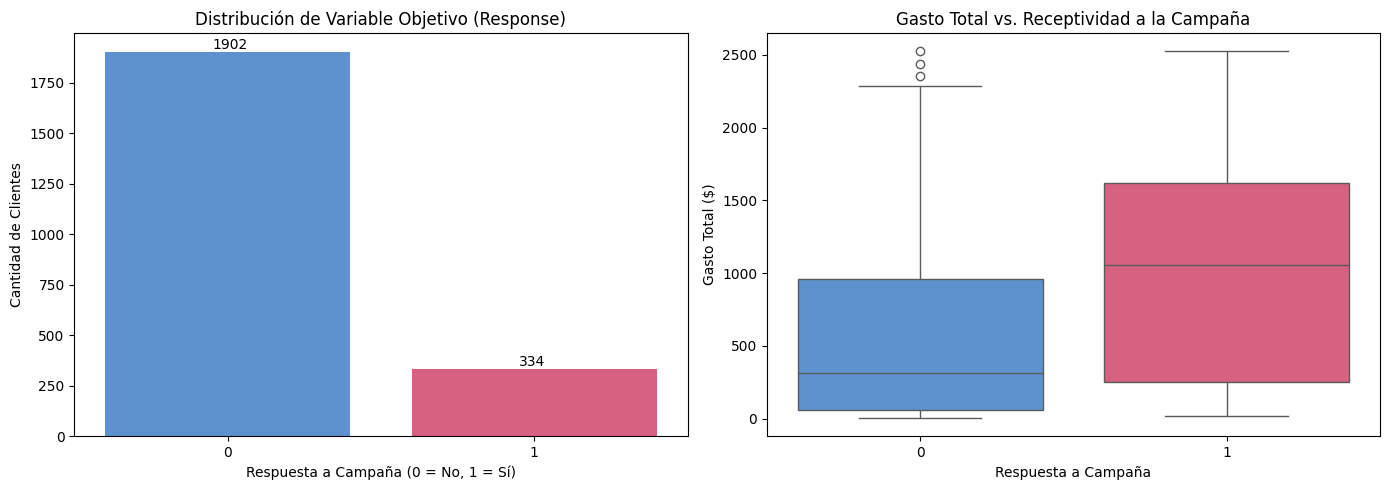

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de la clase Response
sns.countplot(x='Response', data=df, ax=axes[0], palette=['#4A90E2', '#E94E77'])
axes[0].set_title('Distribución de Variable Objetivo (Response)')
axes[0].set_xlabel('Respuesta a Campaña (0 = No, 1 = Sí)')
axes[0].set_ylabel('Cantidad de Clientes')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + 0.35, p.get_height() + 15))

# Distribución del gasto total según respuesta
sns.boxplot(x='Response', y='Total_Spent', data=df, ax=axes[1], palette=['#4A90E2', '#E94E77'])
axes[1].set_title('Gasto Total vs. Receptividad a la Campaña')
axes[1].set_xlabel('Respuesta a Campaña')
axes[1].set_ylabel('Gasto Total ($)')

plt.tight_layout()
plt.savefig('reports/figures/exploracion_inicial.png', dpi=300)
plt.show()

### 4.3 Partición 70/30 y Estandarización (`StandardScaler`)
Aplicamos la **Regla de Oro** del curso: la división entrenamiento/prueba se realiza primero con `random_state=1` y `test_size=0.30`. El escalador `StandardScaler` se ajusta (`fit`) únicamente sobre los datos de entrenamiento y transforma (`transform`) ambos conjuntos para evitar la fuga de datos (*data leakage*).

In [6]:
# Separar Atributos (X) y Clase (y)
X = df.drop(columns=['Response'])
y = df['Response']

# División 70/30 estratificada para mantener la proporción de la clase
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEMILLA, stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} casos")
print(f"Prueba: {X_test.shape[0]} casos")
print(f"Proporción de clase 1 en Train: {y_train.mean():.2%}")
print(f"Proporción de clase 1 en Test: {y_test.mean():.2%}")

# Estandarización con StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# Guardar datos preparados limpios (sin escalar y escalados) para los demás notebooks
df.to_csv('data/processed/data_limpia_original.csv', index=False)

# Guardar train y test listos para modelado
train_processed = X_train_scaled.copy()
train_processed['Response'] = y_train
train_processed.to_csv('data/processed/train_scaled.csv', index=False)

test_processed = X_test_scaled.copy()
test_processed['Response'] = y_test
test_processed.to_csv('data/processed/test_scaled.csv', index=False)

print("\n¡Datos exportados con éxito a 'data/processed/'!")

Entrenamiento: 1565 casos
Prueba: 671 casos
Proporción de clase 1 en Train: 14.95%
Proporción de clase 1 en Test: 14.90%

¡Datos exportados con éxito a 'data/processed/'!
